# RMSD distribution of the training data and the effect of the RMSD cutoff

How much data does `filter_rmsd_max_value` remove at 10 Å vs 20 Å? The filter keeps complexes with `predicted_rmsd ≤ cutoff`. It is applied to **both** datasets **before** the split, so it also changes the test sets.

- **Activity data** (Kinodata-3D, `kinodata_docked_v2.pt`): `predicted_rmsd` is the RMSD *predicted* by the Kinodata-3D docking pipeline for the kept pose. Processing already keeps only the pose with the lowest predicted RMSD per (ligand, kinase, activity type).
- **Pose data** (POSIT cross-docking, `posit_combined.pt`): `predicted_rmsd` holds the *true* RMSD to the crystal pose (same field name).

Pose-quality classes follow the code: q = 1/(1+exp(0.9·(RMSD−4.5))). "Good" q ≥ 0.8 ↔ RMSD ≤ 2.96 Å; "bad" q ≤ 0.2 ↔ RMSD ≥ 6.04 Å; "medium" in between.

The filter compares with `<=`, so complexes **without an RMSD (NaN) are dropped by any cutoff**; they are counted separately below.

The first run reads the unfiltered processed datasets (about 40 GB RAM, a few minutes): **use a compute node**, not the login node. The per-complex table is then cached in `analysis/output/` and later runs only read the cache.

In [1]:
from pathlib import Path

# repo root = first parent folder that contains the kinodata package
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "kinodata" / "__init__.py").exists())
OUTPUT = REPO / "analysis" / "output"
OUTPUT.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROCESSED = REPO / "data" / "processed"
CUTOFFS = [10, 20]
Q_GOOD, Q_BAD = 0.8, 0.2
RMSD_GOOD = 4.5 - np.log(Q_GOOD / (1 - Q_GOOD)) / 0.9   # 2.96 A
RMSD_BAD = 4.5 + np.log((1 - Q_BAD) / Q_BAD) / 0.9      # 6.04 A
SCAFFOLD_CAP = 3000  # pose samples per scaffold in the scaffold split (hard-coded in grouped_split.py)
print(f"good <= {RMSD_GOOD:.2f} A, bad >= {RMSD_BAD:.2f} A")

good <= 2.96 A, bad >= 6.04 A


In [2]:
def per_complex_table(pt_file, cache, keys):
    """predicted_rmsd and metadata of every complex in an unfiltered processed dataset (cached as csv.gz)."""
    if cache.exists():
        return pd.read_csv(cache)
    import torch
    data, _ = torch.load(pt_file)
    store = data._global_store
    cols = {}
    for k in keys:
        if k in store:
            v = store[k]
            cols[k] = v.numpy().ravel() if hasattr(v, "numpy") else list(v)
    df = pd.DataFrame(cols)
    del data
    df.to_csv(cache, index=False)
    return df


activity = per_complex_table(PROCESSED / "kinodata" / "kinodata_docked_v2.pt", OUTPUT / "rmsd_activity.csv.gz",
                             ["predicted_rmsd", "y", "activity_type", "scaffold", "pocket_sequence", "smiles", "ident"])
pose = per_complex_table(PROCESSED / "davidsdocked" / "posit_combined.pt", OUTPUT / "rmsd_pose.csv.gz",
                         ["predicted_rmsd", "scaffold", "pocket_sequence", "smiles", "docking_score", "ident"])
print(f"activity: {len(activity):,} complexes, columns {list(activity.columns)}")
print(f"pose:     {len(pose):,} poses, columns {list(pose.columns)}")

activity: 119,522 complexes, columns ['predicted_rmsd', 'y', 'activity_type', 'scaffold', 'pocket_sequence', 'smiles', 'ident']
pose:     80,155 poses, columns ['predicted_rmsd', 'scaffold', 'pocket_sequence', 'smiles', 'docking_score', 'ident']


## How much each cutoff removes

In [3]:
def cutoff_summary(df, name):
    r = df["predicted_rmsd"]
    rows = [{"dataset": name, "cutoff": "none", "kept": len(df), "removed": 0, "removed %": 0.0,
             "of which no RMSD (NaN)": 0}]
    for c in CUTOFFS:
        kept = int((r <= c).sum())
        rows.append({"dataset": name, "cutoff": f"<= {c} A", "kept": kept, "removed": len(df) - kept,
                     "removed %": round(100 * (len(df) - kept) / len(df), 2),
                     "of which no RMSD (NaN)": int(r.isna().sum())})
    return rows


summary = pd.DataFrame(cutoff_summary(activity, "activity (predicted RMSD)") + cutoff_summary(pose, "pose (true RMSD)"))
summary

,dataset,cutoff,kept,removed,removed %,of which no RMSD (NaN)
0,activity (predicted RMSD),none,119522,0,0.00,0
1,activity (predicted RMSD),<= 10 A,119421,101,0.08,0
2,activity (predicted RMSD),<= 20 A,119522,0,0.00,0
3,pose (true RMSD),none,80155,0,0.00,0
4,pose (true RMSD),<= 10 A,67976,12179,15.19,1392
5,pose (true RMSD),<= 20 A,75216,4939,6.16,1392


In [4]:
for name, df in [("activity", activity), ("pose", pose)]:
    r = df["predicted_rmsd"]
    print(f"{name:9s} RMSD min {r.min():.2f}, median {r.median():.2f}, 90th pct {r.quantile(0.9):.2f}, max {r.max():.2f} A; "
          f"between 10 and 20 A: {int(((r > 10) & (r <= 20)).sum()):,}; above 20 A: {int((r > 20).sum()):,}; "
          f"no RMSD (NaN): {int(r.isna().sum()):,}")

activity  RMSD min -0.94, median 4.14, 90th pct 6.41, max 16.03 A; between 10 and 20 A: 101; above 20 A: 0; no RMSD (NaN): 0
pose      RMSD min 0.08, median 4.36, 90th pct 11.43, max 171.37 A; between 10 and 20 A: 7,240; above 20 A: 3,547; no RMSD (NaN): 1,392


## Pose-quality classes removed by each cutoff

Everything above 10 Å is a "bad" pose (≥ 6.04 Å), so the cutoff removes bad poses only (plus the poses without an RMSD, which every cutoff drops). This matters for the "no pose left behind" framing (R2.1, R2.4).

In [5]:
def quality_class(r):
    return np.select([np.isnan(r), r <= RMSD_GOOD, r >= RMSD_BAD], ["no RMSD", "good", "bad"], "medium")


rows = []
for name, df in [("activity", activity), ("pose", pose)]:
    cls = pd.Series(quality_class(df["predicted_rmsd"].to_numpy()), index=df.index)
    for c in [None] + CUTOFFS:
        keep = np.ones(len(df), bool) if c is None else (df["predicted_rmsd"] <= c).to_numpy()
        counts = cls[keep].value_counts()
        rows.append({"dataset": name, "cutoff": "none" if c is None else f"<= {c} A",
                     **{k: int(counts.get(k, 0)) for k in ["good", "medium", "bad", "no RMSD"]},
                     "bad % (of those with RMSD)": round(100 * counts.get("bad", 0) / (keep.sum() - counts.get("no RMSD", 0)), 1)})
classes = pd.DataFrame(rows)
classes

,dataset,cutoff,good,medium,bad,no RMSD,bad % (of those with RMSD)
0,activity,none,47139,48155,24228,0,20.3
1,activity,<= 10 A,47139,48155,24127,0,20.2
2,activity,<= 20 A,47139,48155,24228,0,20.3
3,pose,none,30985,18553,29225,1392,37.1
4,pose,<= 10 A,30985,18553,18438,0,27.1
5,pose,<= 20 A,30985,18553,25678,0,34.1


## Distributions

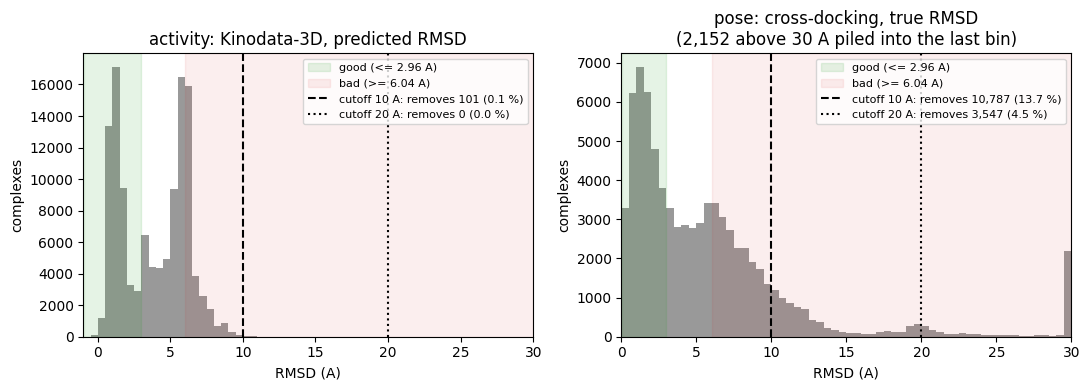

In [6]:
X_MAX = 30  # a few poses go up to ~170 A; they are counted in the title, not drawn
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, df) in zip(axes, [("activity: Kinodata-3D, predicted RMSD", activity), ("pose: cross-docking, true RMSD", pose)]):
    r = df["predicted_rmsd"].dropna()
    ax.hist(r.clip(upper=X_MAX), bins=np.arange(np.floor(r.min()), X_MAX + 0.5, 0.5), color="0.6")
    ax.axvspan(r.min(), RMSD_GOOD, color="tab:green", alpha=0.12, label=f"good (<= {RMSD_GOOD:.2f} A)")
    ax.axvspan(RMSD_BAD, X_MAX, color="tab:red", alpha=0.08, label=f"bad (>= {RMSD_BAD:.2f} A)")
    for c, ls in zip(CUTOFFS, ["--", ":"]):
        ax.axvline(c, color="k", ls=ls, label=f"cutoff {c} A: removes {int((r > c).sum()):,} ({100 * (r > c).mean():.1f} %)")
    n_out = int((r > X_MAX).sum())
    ax.set(title=name + (f"\n({n_out:,} above {X_MAX} A piled into the last bin)" if n_out else ""),
           xlabel="RMSD (A)", ylabel="complexes", xlim=(np.floor(r.min()), X_MAX))
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT / "rmsd_distribution.png", dpi=200)

## What the models actually train on in the scaffold split

The scaffold split caps the pose data at 3000 poses per scaffold. Here the cap is applied as a count, min(n, 3000) per scaffold. For 20 Å this should reproduce the 64,716 pose samples seen in the split logs (2026-10-16).

The table also shows how many scaffolds, pocket sequences (kinases) and ligands each cutoff removes completely.

In [7]:
rows = []
for name, df in [("activity", activity), ("pose", pose)]:
    for c in [None] + CUTOFFS:
        sub = df if c is None else df[df["predicted_rmsd"] <= c]
        row = {"dataset": name, "cutoff": "none" if c is None else f"<= {c} A", "complexes": len(sub),
               "scaffolds": sub["scaffold"].nunique(), "pockets": sub["pocket_sequence"].nunique()}
        if "smiles" in sub:
            row["ligands"] = sub["smiles"].nunique()
        if name == "pose":
            row["after 3000/scaffold cap"] = int(sub.groupby("scaffold").size().clip(upper=SCAFFOLD_CAP).sum())
        rows.append(row)
pd.DataFrame(rows)

,dataset,cutoff,complexes,scaffolds,pockets,ligands,after 3000/scaffold cap
0,activity,none,119522,16361,850,88434,NaN
1,activity,<= 10 A,119421,16348,850,88386,NaN
2,activity,<= 20 A,119522,16361,850,88434,NaN
3,pose,none,80155,1005,131,1843,68409.0
4,pose,<= 10 A,67976,980,131,1789,58934.0
5,pose,<= 20 A,75216,989,131,1806,64716.0


## Are the removed activity complexes different?

Compares the pIC50 (`y`, raw values before z-scoring) of activity complexes kept vs removed by the 10 Å cutoff. If they are similar, the cutoff does not shift the activity distribution.

In [8]:
if "y" in activity:
    r = activity["predicted_rmsd"]
    groups = {"<= 10 A": activity.loc[r <= 10, "y"], "10-20 A": activity.loc[(r > 10) & (r <= 20), "y"], "> 20 A": activity.loc[r > 20, "y"]}
    display(pd.DataFrame({k: v.describe().round(2) for k, v in groups.items()}).T)

,count,mean,std,min,25%,50%,75%,max
<= 10 A,119421.0,7.16,1.29,1.02,6.25,7.28,8.10,14.0
10-20 A,101.0,6.94,1.49,4.00,5.62,7.22,8.05,10.0
> 20 A,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
